# Dynamic rotation: forward solver examples

Examples for `solver_dynamic.py`, which implements `new-notes/rotation_dynamic_2vector.pdf`:
the instantaneous solve $\mathbf j=\mathcal J(\zeta,\boldsymbol\omega)$ (§2.3), the forward right-hand side
$\dot{\boldsymbol\omega}=\mathbf f(\boldsymbol\omega,t)$ with $\dot{\mathbf j}=\mathcal J(\dot\zeta,\dot{\boldsymbol\omega})$ (§4.3), and time
integration (§4.4). Elastic Earth, hydrostatic ocean, no core, no damping; equatorial rotation only.

All runs use RK4 unless stated. Resolution and step sizes are set in the parameters cell. The values
quoted from the note are for degree 64, so runs at a lower degree differ slightly where the ocean is involved.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from pyslfp.physics import SeaLevelEquation

import solver_dynamic as sd
import examples_dynamic_helper as eh

/space/dah94/rotation/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 0. Parameters, Earth model and loads

In [2]:
#=======================================================================
# Parameters
#=======================================================================

lmax = 32
rtol = 1e-10
year_days = 365.25

# Size of the free wobble and of the Y21 load's static pole shift (mas)
wobble_mas = 100.0

# Fraction of Northern Hemisphere ice used for the hemispheric load
nh_fraction = 1e-3

# Time steps (days) and run lengths (years)
dt_free_days = 7.0
free_years = 3.0
dt_ramp_days = 30.0
ramp_years = 20.0
step_ramp_days = 1e-4
dt_step_days = 1.0
dt_step_ocean_days = 7.0
step_years = 3.0
periodic_steps_per_period = 40
periodic_years = 4.0
dt_annual_days = 7.0
annual_years = 6.0

In [3]:
#=======================================================================
# Earth model and constants
#=======================================================================

state = sd.make_state(lmax)
model = state.model
constants = sd.rotation_constants(model)

# Unit conversions: the solver works in non-dimensional time
day = float(sd.days_to_model_time(1.0, constants))
year = year_days * day
length_scale_mm = constants["length_scale"] * 1e3

print(f"lmax = {lmax}; Omega = {constants['omega'] / constants['time_scale']:.7e} rad/s (sidereal)")
print(f"(I3 - I1) / I1 = {constants['di'] / constants['i1']:.4e}")

lmax = 32; Omega = 7.2921150e-05 rad/s (sidereal)
(I3 - I1) / I1 = 3.2836e-03


In [4]:
#=======================================================================
# Loads used below
#=======================================================================

zero_load = model.zero_grid()
no_load = sd.SeparableLoad([(zero_load, 0.0)])

# Degree-2, order-1 loads (cosine and sine), scaled to a static pole shift of wobble_mas
y21c_unit = sd.harmonic_load(model, 2, 1)
static_unit = sd.equilibrium_rotation(state, constants, y21c_unit, ocean=False)
y21_amplitude = wobble_mas / sd.omega_to_mas(static_unit["omega"][0], constants)
y21c_load = sd.harmonic_load(model, 2, 1, amplitude=y21_amplitude)
y21s_load = sd.harmonic_load(model, 2, 1, sine=True, amplitude=y21_amplitude)

# Hemispheric load: melt a small fraction of Northern Hemisphere ice
nh_load = state.northern_hemisphere_load(fraction=nh_fraction)

# Static responses (AA24), from the equilibrium iteration of §4.4
static_y21 = sd.equilibrium_rotation(state, constants, y21c_load, ocean=False)
static_nh = sd.equilibrium_rotation(state, constants, nh_load, rtol=1e-12)

# Initial wobble giving a pole offset of wobble_mas
omega_wobble = np.array([wobble_mas / sd.omega_to_mas(1.0, constants), 0.0])

print(f"static pole shift: Y21 (no ocean) {sd.omega_to_mas(static_y21['omega'], constants)} mas, "
      f"hemispheric (ocean) {sd.omega_to_mas(static_nh['omega'], constants)} mas")

static pole shift: Y21 (no ocean) [1.00000000e+02 2.59043617e-15] mas, hemispheric (ocean) [ 22.95131696 -17.20676661] mas


## 1. Free wobble

No load, a prescribed $\boldsymbol\omega_0$, with and without the ocean. The note's periods (§5.3, degree 64) are 444.24 d
without an ocean and 476.73 d with it. The no-ocean case is repeated with the trapezoidal rule, which lengthens the period
by about $(\sigma'_{\rm CW}\Delta t)^2/12$, and with `solve_ivp` (Dormand–Prince), to show that the integrator can be swapped. Without an ocean the path is a circle, so $|\boldsymbol\omega|$ max/min measures the
integrator's amplitude error. With the ocean it is a slightly elliptical path, because the ocean pole tide is not axisymmetric.

In [5]:
#=======================================================================
# Free wobble, with and without the ocean
#=======================================================================

t_free = np.arange(0.0, free_years * year, dt_free_days * day)
t_free_days = sd.model_time_to_days(t_free, constants)

rhs_free_no_ocean = sd.forward_rhs(state, constants, no_load, ocean=False, rtol=rtol)
rhs_free_ocean = sd.forward_rhs(state, constants, no_load, ocean=True, rtol=rtol)

start_time = time.time()
free_no_ocean = sd.integrate(rhs_free_no_ocean, omega_wobble, t_free)
free_ocean = sd.integrate(rhs_free_ocean, omega_wobble, t_free)
print(f"RK4 runs took {time.time() - start_time:.1f} s; "
      f"mean inner iterations (ocean) {np.mean(rhs_free_ocean.inner_iterations):.1f}")

# The same no-ocean run with the trapezoidal rule and with solve_ivp
free_trapezoid = sd.integrate(rhs_free_no_ocean, omega_wobble, t_free, step=sd.trapezoid_step)
solution = solve_ivp(
    rhs_free_no_ocean,
    (t_free[0], t_free[-1]),
    omega_wobble,
    method="DOP853",
    rtol=1e-10,
    atol=1e-12 * np.abs(omega_wobble).max(),
    t_eval=t_free,
)
free_dop853 = solution.y.T

t_cw_no_ocean = eh.wobble_period_days(t_free_days, free_no_ocean)
t_cw_ocean = eh.wobble_period_days(t_free_days, free_ocean)
for label, run in [
    ("no ocean, RK4", free_no_ocean),
    ("no ocean, trapezoid", free_trapezoid),
    ("no ocean, DOP853", free_dop853),
    ("ocean, RK4", free_ocean),
]:
    amplitude = np.linalg.norm(run, axis=1)
    print(f"{label:20s}: period {eh.wobble_period_days(t_free_days, run):.3f} d, "
          f"|omega| max / min {amplitude.max() / amplitude.min():.7f}")

RK4 runs took 28.3 s; mean inner iterations (ocean) 5.0


no ocean, RK4       : period 444.243 d, |omega| max / min 1.0000010
no ocean, trapezoid : period 444.606 d, |omega| max / min 1.0000000
no ocean, DOP853    : period 444.243 d, |omega| max / min 1.0000000
ocean, RK4          : period 476.662 d, |omega| max / min 1.0087316


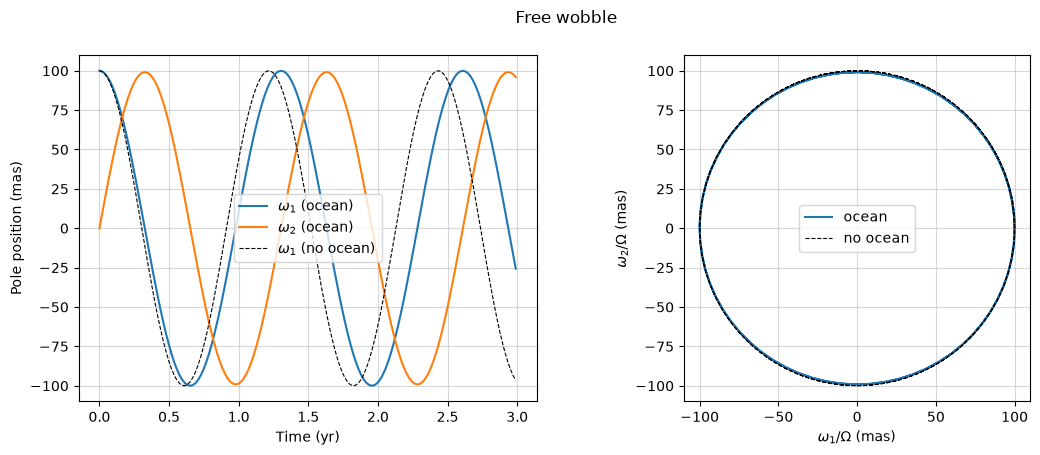

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

pole_ocean = sd.omega_to_mas(free_ocean, constants)
pole_no_ocean = sd.omega_to_mas(free_no_ocean, constants)

axes[0].plot(t_free_days / year_days, pole_ocean[:, 0], label=r"$\omega_1$ (ocean)")
axes[0].plot(t_free_days / year_days, pole_ocean[:, 1], label=r"$\omega_2$ (ocean)")
axes[0].plot(t_free_days / year_days, pole_no_ocean[:, 0], "k--", lw=0.8, label=r"$\omega_1$ (no ocean)")
axes[0].set_xlabel("Time (yr)")
axes[0].set_ylabel("Pole position (mas)")
axes[0].legend()
axes[0].grid(True, alpha=0.5)

axes[1].plot(pole_ocean[:, 0], pole_ocean[:, 1], label="ocean")
axes[1].plot(pole_no_ocean[:, 0], pole_no_ocean[:, 1], "k--", lw=0.8, label="no ocean")
axes[1].set_xlabel(r"$\omega_1/\Omega$ (mas)")
axes[1].set_ylabel(r"$\omega_2/\Omega$ (mas)")
axes[1].set_aspect("equal")
axes[1].legend()
axes[1].grid(True, alpha=0.5)

fig.suptitle("Free wobble")
plt.show()

## 2. Static checks

(a) Starting from equilibrium with a constant load, nothing should move.
(b) The equilibrium iteration agrees with pyslfp's static solver, up to the axial rotation $\omega_3$, which pyslfp includes
and this solver omits.

In [7]:
#=======================================================================
# (a) Constant load from equilibrium
#=======================================================================

constant_nh = sd.SeparableLoad([(nh_load, 1.0)])
rhs_constant = sd.forward_rhs(state, constants, constant_nh, rtol=1e-12)
t_constant = np.arange(0.0, 2 * year, dt_ramp_days * day)

omega_constant = sd.integrate(rhs_constant, static_nh["omega"], t_constant)
drift = np.abs(omega_constant - static_nh["omega"]).max() / np.abs(static_nh["omega"]).max()
print(f"(a) max drift of omega over 2 yr from equilibrium, relative: {drift:.1e}")

#=======================================================================
# (b) Equilibrium iteration vs pyslfp's static solver
#=======================================================================

sle = SeaLevelEquation(model)
slc_pyslfp, _, _, omega_pyslfp = sle.solve_sea_level_equation(state, nh_load, rtol=1e-12)
omega_difference = np.linalg.norm(static_nh["omega"] - omega_pyslfp[:2]) / np.linalg.norm(omega_pyslfp[:2])
slc_difference = np.abs(static_nh["sea_level"].data - slc_pyslfp.data).max() / np.abs(slc_pyslfp.data).max()
print(f"(b) omega: equilibrium {static_nh['omega']}, pyslfp {omega_pyslfp}")
print(f"    relative differences: omega {omega_difference:.1e}, sea level {slc_difference:.1e}")

(a) max drift of omega over 2 yr from equilibrium, relative: 6.1e-13
(b) omega: equilibrium [ 6.53369854e-09 -4.89836057e-09], pyslfp [ 6.53364420e-09 -4.89835353e-09 -3.76804660e-11]
    relative differences: omega 6.7e-06, sea level 6.3e-05


## 3. Slow ramp of a hemispheric load

The hemispheric load rises linearly over 20 years, from rest, with the ocean. The pole follows the static pole with
an offset at right angles to the drift, equal to the static drift over $1/\sigma'_{\rm CW}+1/\Omega=70.86$ d (note §5.4),
plus a free wobble of the same size.

Run took 33.2 s
max |omega - omega_static| / |final static omega| = 2.07e-02 (offset 9.70e-03; with the free wobble the deviation reaches about twice that)


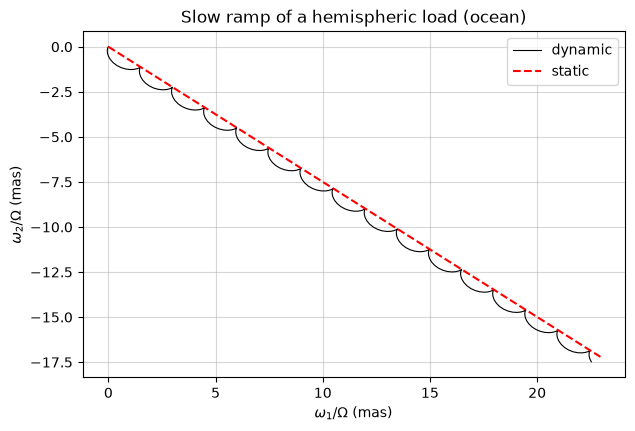

In [8]:
#=======================================================================
# Slow ramp from rest
#=======================================================================

ramp_nh = sd.SeparableLoad([(nh_load, sd.LinearRamp(ramp_years * year))])
rhs_ramp = sd.forward_rhs(state, constants, ramp_nh, rtol=rtol)
t_ramp = np.arange(0.0, ramp_years * year + 0.5 * dt_ramp_days * day, dt_ramp_days * day)

start_time = time.time()
omega_ramp = sd.integrate(rhs_ramp, np.zeros(2), t_ramp)
print(f"Run took {time.time() - start_time:.1f} s")

ramp_amplitude = np.array([ramp_nh.terms[0][1].value(t) for t in t_ramp])
omega_static_ramp = np.outer(ramp_amplitude, static_nh["omega"])

deviation = np.linalg.norm(omega_ramp - omega_static_ramp, axis=1)
offset_expected = 70.86 / (ramp_years * year_days)
print(f"max |omega - omega_static| / |final static omega| = {deviation.max() / np.linalg.norm(static_nh['omega']):.2e} "
      f"(offset {offset_expected:.2e}; with the free wobble the deviation reaches about twice that)")

fig, ax = plt.subplots(figsize=(7, 4.5))
pole_ramp = sd.omega_to_mas(omega_ramp, constants)
pole_static_ramp = sd.omega_to_mas(omega_static_ramp, constants)
ax.plot(pole_ramp[:, 0], pole_ramp[:, 1], "k", lw=0.8, label="dynamic")
ax.plot(pole_static_ramp[:, 0], pole_static_ramp[:, 1], "r--", label="static")
ax.set_xlabel(r"$\omega_1/\Omega$ (mas)")
ax.set_ylabel(r"$\omega_2/\Omega$ (mas)")
ax.set_title("Slow ramp of a hemispheric load (ocean)")
ax.legend()
ax.grid(True, alpha=0.5)
plt.show()

## 4. Smoothed step load

A true step has $\dot\zeta$ equal to a $\delta$-function, so the load is switched on over a cosine ramp instead. The ramp here
lasts $10^{-4}$ d, well below $1/\Omega$, so it behaves as a step. (That timescale is outside the model's range of validity,
which assumes forcing periods much longer than a day, but it tests the $\dot{\mathbf j}$ physics.) Across a step the angular
momentum $I_1\boldsymbol\omega+\mathbf j$ is conserved, so $\boldsymbol\omega$ jumps slightly the wrong way and then circles the static value.
Without an ocean the note gives the jump as $-\sigma'_{\rm CW}/\Omega=-2.245\times10^{-3}$ of the static response (§5.4).

In [9]:
#=======================================================================
# Time levels: fine steps across the ramp, then ordinary steps
#=======================================================================

def step_times(dt_days):
    t_fine = np.linspace(0.0, step_ramp_days * day, 21)
    t_coarse = np.arange(t_fine[-1] + dt_days * day, step_years * year, dt_days * day)
    return np.concatenate([t_fine, t_coarse]), len(t_fine) - 1

step_amplitude = sd.CosineRamp(step_ramp_days * day)

#=======================================================================
# Without an ocean: Y21 load
#=======================================================================

step_y21 = sd.SeparableLoad([(y21c_load, step_amplitude)])
t_step, n_after = step_times(dt_step_days)
omega_step = sd.integrate(sd.forward_rhs(state, constants, step_y21, ocean=False), np.zeros(2), t_step)

j_after = sd.solve_instantaneous(state, constants, step_y21.value(t_step[n_after]), omega_step[n_after], ocean=False)["j"]
momentum_after = constants["i1"] * omega_step[n_after] + j_after
print(f"No ocean: |I1 omega + j| / |j| after the ramp {np.linalg.norm(momentum_after) / np.linalg.norm(j_after):.1e}")
print(f"          jump / static {omega_step[n_after, 0] / static_y21['omega'][0]:.5e} (note: -2.245e-03)")

#=======================================================================
# With the ocean: hemispheric load
#=======================================================================

step_nh = sd.SeparableLoad([(nh_load, step_amplitude)])
t_step_ocean, n_after_ocean = step_times(dt_step_ocean_days)

start_time = time.time()
omega_step_ocean = sd.integrate(sd.forward_rhs(state, constants, step_nh, rtol=rtol), np.zeros(2), t_step_ocean)
print(f"Ocean run took {time.time() - start_time:.1f} s")

j_after_ocean = sd.solve_instantaneous(
    state,
    constants,
    step_nh.value(t_step_ocean[n_after_ocean]),
    omega_step_ocean[n_after_ocean],
    rtol=rtol,
)["j"]
momentum_after_ocean = constants["i1"] * omega_step_ocean[n_after_ocean] + j_after_ocean
print(f"Ocean:    |I1 omega + j| / |j| after the ramp {np.linalg.norm(momentum_after_ocean) / np.linalg.norm(j_after_ocean):.1e}")

No ocean: |I1 omega + j| / |j| after the ramp 3.2e-04
          jump / static -2.24488e-03 (note: -2.245e-03)


Ocean run took 26.8 s
Ocean:    |I1 omega + j| / |j| after the ramp 3.2e-04


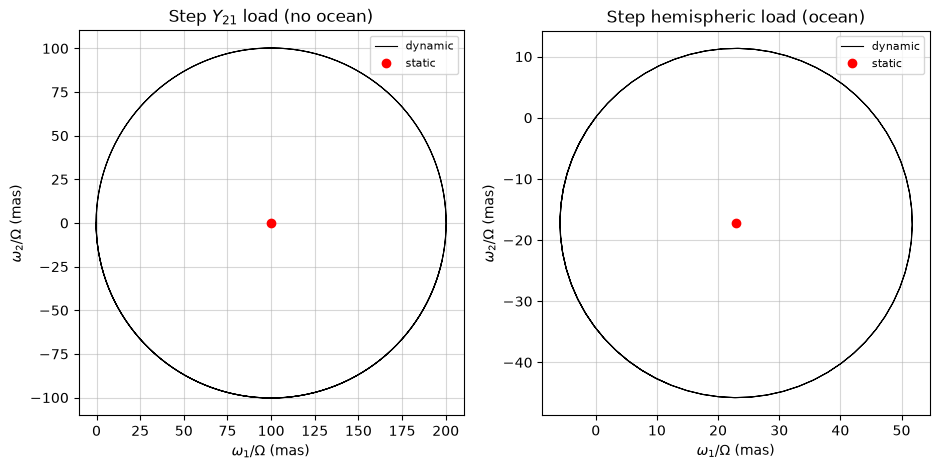

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, run, static, title in [
    (axes[0], omega_step, static_y21, r"Step $Y_{21}$ load (no ocean)"),
    (axes[1], omega_step_ocean, static_nh, "Step hemispheric load (ocean)"),
]:
    pole_step = sd.omega_to_mas(run, constants)
    pole_static_step = sd.omega_to_mas(static["omega"], constants)
    ax.plot(pole_step[:, 0], pole_step[:, 1], "k", lw=0.8, label="dynamic")
    ax.plot(*pole_static_step, "ro", label="static")
    ax.set_xlabel(r"$\omega_1/\Omega$ (mas)")
    ax.set_ylabel(r"$\omega_2/\Omega$ (mas)")
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(True, alpha=0.5)
plt.show()

## 5. Periodic loads

**(a)** Circular $Y_{21}$ forcing, $\zeta=\cos\nu t\,Y^c_{21}\pm\sin\nu t\,Y^s_{21}$ (+ prograde, − retrograde), with no ocean, started
from equilibrium. The forced part is separated from the free wobble by a least-squares fit, and its ratio to the static
response is compared with the table of the note (§5.4).

In [11]:
#=======================================================================
# (a) Forced response at the note's three periods
#=======================================================================

def circular_load(period_days, direction):
    nu = 2 * np.pi / (period_days * day)
    return sd.SeparableLoad([
        (y21c_load, sd.Sinusoid(nu, np.pi / 2)),
        (y21s_load, direction * sd.Sinusoid(nu)),
    ])


def forced_ratio(period_days, direction):
    load = circular_load(period_days, direction)
    omega_0 = sd.equilibrium_rotation(state, constants, load.value(0.0), ocean=False)["omega"]
    t = np.arange(0.0, periodic_years * year, period_days / periodic_steps_per_period * day)
    omega = sd.integrate(sd.forward_rhs(state, constants, load, ocean=False), omega_0, t)
    coefficients = eh.fit_forced_response(
        sd.model_time_to_days(t, constants),
        omega,
        2 * np.pi / period_days,
        2 * np.pi / t_cw_no_ocean,
    )
    forced = coefficients[0] if direction == 1 else coefficients[1]
    return (forced / static_y21["omega"][0]).real


note_table = {
    (30.0, 1): -0.0748,
    (182.625, 1): -0.7019,
    (365.25, 1): -4.6365,
    (30.0, -1): 0.0612,
    (182.625, -1): 0.2897,
    (365.25, -1): 0.4500,
}

start_time = time.time()
table_points = []
for (period_days, direction), note_value in note_table.items():
    ratio = forced_ratio(period_days, direction)
    table_points.append((direction * period_days, ratio))
    label = "prograde" if direction == 1 else "retrograde"
    print(f"{period_days:8.3f} d {label:10s}: simulated {ratio: .4f}, note {note_value: .4f}")
print(f"Runs took {time.time() - start_time:.1f} s")

  30.000 d prograde  : simulated -0.0748, note -0.0748


 182.625 d prograde  : simulated -0.7019, note -0.7019


 365.250 d prograde  : simulated -4.6364, note -4.6365


  30.000 d retrograde: simulated  0.0612, note  0.0612


 182.625 d retrograde: simulated  0.2897, note  0.2897


 365.250 d retrograde: simulated  0.4500, note  0.4500
Runs took 65.5 s


**(b)** Sweep of the forcing period with the same runs. The prograde response is resonant at the Chandler period (from
section 1); the retrograde response is not. Periods close to resonance are skipped, where the fit cannot separate the
forced and free parts.

Sweep took 120.8 s


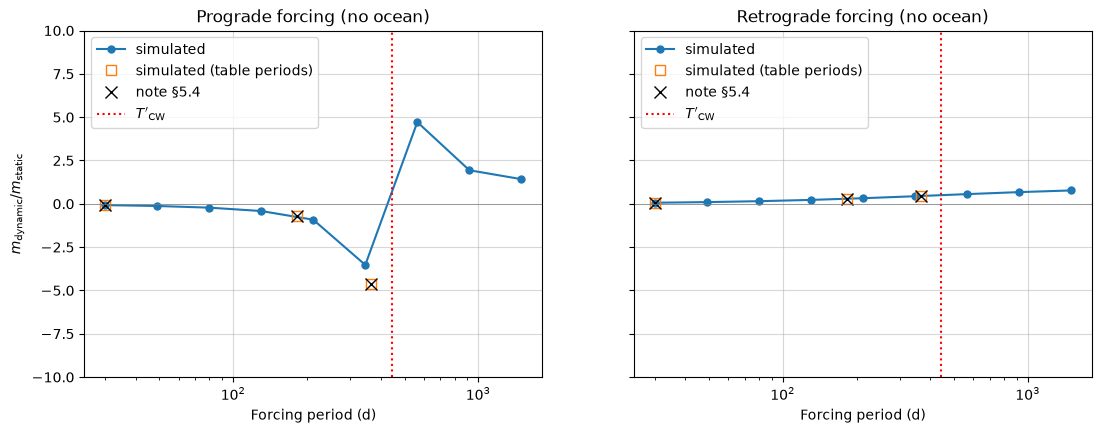

In [12]:
#=======================================================================
# (b) Sweep of forcing period
#=======================================================================

periods_sweep = np.geomspace(30.0, 1500.0, 9)
periods_sweep = periods_sweep[np.abs(periods_sweep / t_cw_no_ocean - 1) > 0.15]

start_time = time.time()
sweep_points = np.array([
    (direction * period_days, forced_ratio(period_days, direction))
    for period_days in periods_sweep
    for direction in [1, -1]
])
print(f"Sweep took {time.time() - start_time:.1f} s")
table_points = np.array(table_points)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, direction, title in [(axes[0], 1, "Prograde"), (axes[1], -1, "Retrograde")]:
    sweep = sweep_points[np.sign(sweep_points[:, 0]) == direction]
    table = table_points[np.sign(table_points[:, 0]) == direction]
    note = np.array([(p, v) for (p, d), v in note_table.items() if d == direction])
    ax.plot(np.abs(sweep[:, 0]), sweep[:, 1], "o-", color="tab:blue", ms=5, label="simulated")
    ax.plot(np.abs(table[:, 0]), table[:, 1], "s", color="tab:orange", ms=7, mfc="none", label="simulated (table periods)")
    ax.plot(note[:, 0], note[:, 1], "kx", ms=8, label="note §5.4")
    ax.axvline(t_cw_no_ocean, color="r", ls=":", label=r"$T'_{\rm CW}$")
    ax.axhline(0, color="grey", lw=0.5)
    ax.set_xscale("log")
    ax.set_ylim(-10, 10)
    ax.set_xlabel("Forcing period (d)")
    ax.set_title(f"{title} forcing (no ocean)")
    ax.grid(True, alpha=0.5)
    ax.legend()
axes[0].set_ylabel(r"$m_{\rm dynamic} / m_{\rm static}$")
plt.show()

**(c)** An annual hemispheric load with the ocean, $\zeta=\sin(2\pi t/1\,{\rm yr})\,\zeta_{\rm NH}$, from rest. Dynamic and static
polar motion are compared.

Run took 48.4 s; mean inner iterations 4.8


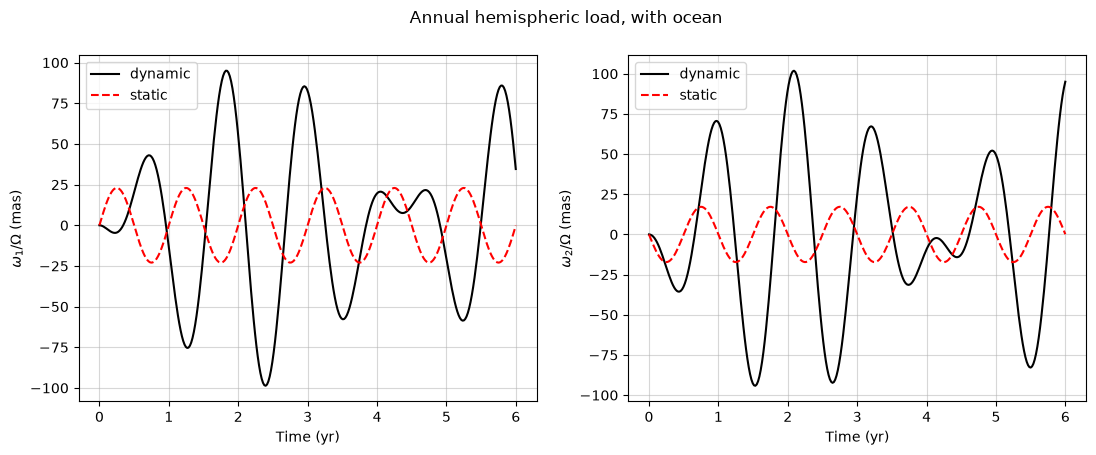

In [13]:
#=======================================================================
# (c) Annual hemispheric load with the ocean
#=======================================================================

annual_amplitude = sd.Sinusoid(2 * np.pi / year)
annual_nh = sd.SeparableLoad([(nh_load, annual_amplitude)])
rhs_annual = sd.forward_rhs(state, constants, annual_nh, rtol=rtol)
t_annual = np.arange(0.0, annual_years * year, dt_annual_days * day)
t_annual_days = sd.model_time_to_days(t_annual, constants)

start_time = time.time()
omega_annual = sd.integrate(rhs_annual, np.zeros(2), t_annual)
print(f"Run took {time.time() - start_time:.1f} s; mean inner iterations {np.mean(rhs_annual.inner_iterations):.1f}")

phase = np.array([annual_amplitude.value(t) for t in t_annual])
omega_static_annual = np.outer(phase, static_nh["omega"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
pole_annual = sd.omega_to_mas(omega_annual, constants)
pole_static_annual = sd.omega_to_mas(omega_static_annual, constants)
for i, ax in enumerate(axes):
    ax.plot(t_annual_days / year_days, pole_annual[:, i], "k", label="dynamic")
    ax.plot(t_annual_days / year_days, pole_static_annual[:, i], "r--", label="static")
    ax.set_xlabel("Time (yr)")
    ax.set_ylabel(rf"$\omega_{i + 1}/\Omega$ (mas)")
    ax.legend()
    ax.grid(True, alpha=0.5)
fig.suptitle("Annual hemispheric load, with ocean")
plt.show()

## 6. Sea level: dynamic and dynamic minus static

The sea level at one time of the annual run (5c) is one more solve with $\zeta(t)$ and $\boldsymbol\omega(t)$. The static sea level
is the equilibrium solution scaled by the load's phase.

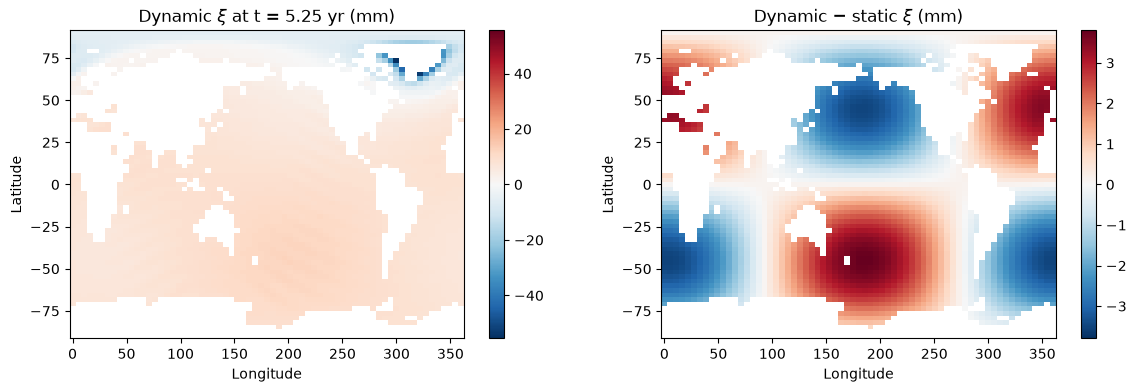

max |dynamic - static| / max |static| over the ocean: 6.73e-02


In [14]:
#=======================================================================
# Sea level at one time of the annual run (mm)
#=======================================================================

n_map = len(t_annual) - 40
slc_dynamic = sd.sea_level(state, constants, annual_nh, t_annual[n_map], omega_annual[n_map], rtol=rtol).data * length_scale_mm
slc_static = phase[n_map] * static_nh["sea_level"].data * length_scale_mm
ocean_mask = np.where(state.ocean_function.data > 0, 1.0, np.nan)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, field, title in [
    (axes[0], slc_dynamic * ocean_mask, rf"Dynamic $\xi$ at t = {t_annual_days[n_map] / year_days:.2f} yr (mm)"),
    (axes[1], (slc_dynamic - slc_static) * ocean_mask, r"Dynamic $-$ static $\xi$ (mm)"),
]:
    image = ax.pcolormesh(state.lons(), state.lats(), field, cmap="RdBu_r", shading="auto")
    limit = np.nanmax(np.abs(field))
    image.set_clim(-limit, limit)
    fig.colorbar(image, ax=ax)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(title)
plt.show()

print(f"max |dynamic - static| / max |static| over the ocean: "
      f"{np.nanmax(np.abs((slc_dynamic - slc_static) * ocean_mask)) / np.nanmax(np.abs(slc_static * ocean_mask)):.2e}")